# Analisis Performa Pemrosesan Gambar — Sequential Baseline

Pada project ini saya ingin membandingkan pemrosesan gambar secara sequential, multithreading, dan multiprocessing. Saya memulai dari sequential supaya punya hasil awal yang bisa dijadikan acuan ketika metode lain diuji.

Pertanyaan pada tahap ini adalah: **bagaimana perbedaan waktu eksekusi, throughput, CPU, dan RAM ketika gambar yang sama diproses dengan workload ringan dan berat?**

Eksperimen saya dijalankan secara lokal di Windows. Notebook ini berisi penjelasan, kode, hasil pengukuran, dan analisis sementara. Angka yang ditampilkan berasal dari program yang dijalankan, sehingga bisa berubah ketika eksperimen diulang.

## 1. Menyiapkan environment

Saya menggunakan environment `.venv` milik project ini. NumPy membaca data gambar, Pillow menjalankan transformasi, psutil mencatat resource proses, pandas menyusun tabel, dan Matplotlib menampilkan grafik.

Kode pengolahan saya pisahkan ke folder `src` supaya notebook lebih mudah dibaca. Cell di bawah memastikan notebook menemukan folder project dan memakai interpreter yang sesuai.

In [1]:
from pathlib import Path
import sys
import subprocess
import json
import inspect
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image as NotebookImage

PROJECT = Path.cwd().resolve()
if not (PROJECT / "src" / "dataset.py").exists():
    raise RuntimeError("Buka notebook dari folder Operating-System-Assignment.")
PYTHON = PROJECT / ".venv" / "Scripts" / "python.exe"
if Path(sys.prefix).resolve() != (PROJECT / ".venv").resolve():
    raise RuntimeError("Pilih kernel Python dari .venv project ini.")
sys.path.insert(0, str(PROJECT / "src"))
from dataset import load_batch, load_label_names
from image_processing import process_image, TRANSFORM_CONFIG
from sequential import run_sequential

print("Folder project:", PROJECT)
print("Python notebook:", sys.executable)
print("Python eksperimen:", PYTHON)

Folder project: C:\Lucky\Binus University\S9\Operating System\Operating-System-Assignment
Python notebook: C:\Lucky\Binus University\S9\Operating System\Operating-System-Assignment\.venv\Scripts\python.exe
Python eksperimen: C:\Lucky\Binus University\S9\Operating System\Operating-System-Assignment\.venv\Scripts\python.exe


## 2. Memeriksa dataset

Saya memakai `data_batch_1.bin`, yaitu batch pertama CIFAR-10 dengan 10.000 gambar RGB berukuran 32 × 32 piksel. Label hanya membantu saya melihat isi gambar dan tidak digunakan dalam pemrosesan.

Bentuk array `(10000, 32, 32, 3)` berarti ada 10.000 gambar, tinggi 32, lebar 32, dan tiga kanal warna. Saya memakai batch yang sama pada seluruh pengulangan supaya jumlah dan isi input tetap sama.

Bentuk array: (10000, 32, 32, 3)
Tipe data: uint8
Contoh kelas: frog


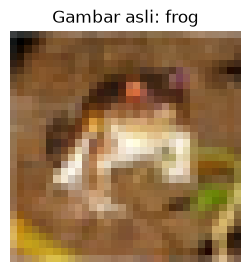

In [2]:
images, labels = load_batch("data_batch_1.bin")
class_names = load_label_names()
assert images.shape == (10000, 32, 32, 3)
print("Bentuk array:", images.shape)
print("Tipe data:", images.dtype)
print("Contoh kelas:", class_names[int(labels[0])])
plt.figure(figsize=(3, 3))
plt.imshow(images[0])
plt.title("Gambar asli: " + class_names[int(labels[0])])
plt.axis("off")
plt.show()

## 3. Menentukan workload

Saya membuat dua pipeline dengan parameter tetap, tanpa transformasi acak:

| Workload | Urutan transformasi |
|---|---|
| LIGHT | Resize ke 64 × 64 → grayscale |
| HEAVY | Resize ke 64 × 64 → rotate 15° → Gaussian blur radius 2 → sharpen → color factor 1,2 → edge detection |

Ukuran 64 × 64 menjadi ukuran kerja yang sama pada kedua workload. Input aslinya tetap 32 × 32; resize memperbesar jumlah piksel yang diproses, bukan menambah detail asli gambar. HEAVY dipakai untuk menambah pekerjaan komputasi, bukan untuk membuat gambar terlihat lebih bagus. Rotate menggunakan `expand=False`, sehingga bagian sudut bisa terpotong.

Saya menampilkan fungsi yang benar-benar dipakai program dan contoh hasilnya di bawah, supaya hubungan antara kode dan output terlihat.

def process_image(pixels: np.ndarray, workload: str) -> Image.Image:
    if workload not in WORKLOADS:
        raise ValueError(f"Workload tidak dikenal: {workload}")
    image = Image.fromarray(pixels).resize(OUTPUT_SIZE, Image.Resampling.BILINEAR)
    if workload == "light":
        return image.convert("L")
    image = image.rotate(15, resample=Image.Resampling.BILINEAR, expand=False)
    image = image.filter(ImageFilter.GaussianBlur(radius=2))
    image = image.filter(ImageFilter.SHARPEN)
    image = ImageEnhance.Color(image).enhance(1.2)
    return image.filter(ImageFilter.FIND_EDGES)

Parameter: {'resize': [64, 64], 'resampling': 'BILINEAR', 'light': ['resize', 'grayscale'], 'heavy': ['resize', 'rotate', 'gaussian_blur', 'sharpen', 'color', 'find_edges'], 'rotation_degrees': 15, 'rotation_expand': False, 'blur_radius': 2, 'color_factor': 1.2}


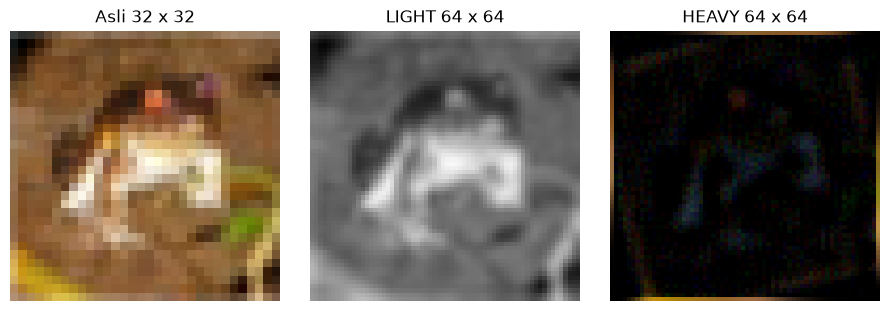

In [3]:
print(inspect.getsource(process_image))
print("Parameter:", TRANSFORM_CONFIG)
light_example = process_image(images[0], "light")
heavy_example = process_image(images[0], "heavy")
assert light_example.size == heavy_example.size == (64, 64)
assert light_example.mode == "L" and heavy_example.mode == "RGB"
fig, axes = plt.subplots(1, 3, figsize=(9, 3), constrained_layout=True)
for ax, image, title in zip(axes, [images[0], light_example, heavy_example],
                           ["Asli 32 x 32", "LIGHT 64 x 64", "HEAVY 64 x 64"]):
    ax.imshow(image, cmap="gray" if title.startswith("LIGHT") else None, vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.show()

## 4. Cara kerja sequential dan pengukuran

Sequential pada program ini memakai satu loop. Gambar berikutnya baru diproses setelah gambar sebelumnya selesai. Saya tidak membuat worker tambahan untuk pengolahan gambar.

Setiap output dimasukkan ke hash SHA-256 dan kemudian tidak disimpan sebagai kumpulan gambar. Hash dipakai untuk memastikan output workload yang sama konsisten antar-run. Kebijakan ini menekan kebutuhan RAM output dan harus dipertahankan ketika metode lain diuji.

| Metrik | Cara saya mengukurnya |
|---|---|
| Execution time | Selisih `perf_counter()` sebelum dan sesudah loop |
| Throughput | Jumlah gambar / waktu pemrosesan |
| CPU proses | 100 × perubahan CPU time proses / waktu pemrosesan |
| Kapasitas CPU mesin | CPU proses / jumlah logical CPU; bukan total CPU seluruh sistem |
| RSS maksimum tersampel | Sampel RAM proses di awal dan setiap 100 gambar |
| Speedup sequential | 1,00 sebagai baseline |

Pada skala CPU proses, 100% setara penggunaan satu logical CPU selama interval pengukuran. Angka ini berbeda dari persentase CPU keseluruhan di Task Manager. RSS sudah mencakup interpreter, library, dan dataset. Saya menyebutnya *maksimum tersampel* karena puncak singkat di antara dua sampel mungkin tidak tercatat.

Timer mencakup konversi array ke gambar, transformasi, hash output, loop, dan sampling RSS. Download, load dataset, warm-up, penulisan file, pembuatan grafik, serta startup proses berada di luar timer. Artinya, ini adalah pengukuran pipeline in-memory, bukan total waktu dari membuka program sampai selesai.

In [4]:
print(inspect.getsource(run_sequential))

def run_sequential(images: np.ndarray, workload: str, sample_every: int = 100) -> dict:
    if len(images) < 1 or sample_every < 1:
        raise ValueError("Jumlah gambar dan interval sampel harus positif")
    gc.collect()
    process = psutil.Process()
    rss_before = process.memory_info().rss / 1024**2
    samples = [{"processed_images": 0, "elapsed_s": 0.0, "rss_mib": rss_before}]
    digest = hashlib.sha256()
    cpu_before = process.cpu_times()
    start = perf_counter()
    for index, pixels in enumerate(images, start=1):
        result = process_image(pixels, workload)
        # Hash membuktikan hasil tiap pengulangan sama tanpa menyimpan 10.000 gambar.
        digest.update(result.tobytes())
        if index % sample_every == 0 or index == len(images):
            samples.append({
                "processed_images": index,
                "elapsed_s": perf_counter() - start,
                "rss_mib": process.memory_info().rss / 1024**2,
            })
    elapsed = perf_cou

## 5. Menjalankan eksperimen

Saya memakai 10.000 gambar dan tiga pengulangan untuk setiap workload. Sebelum pengukuran, 50 gambar diproses sebagai warm-up pada masing-masing workload. Urutannya bergantian: LIGHT–HEAVY, HEAVY–LIGHT, lalu LIGHT–HEAVY. Ini membantu mengurangi pengaruh urutan, tetapi tidak membuat komputer bebas dari aktivitas background.

Cell ini menjalankan `main.py` di proses Python terpisah. Pengolahan gambar di dalam proses tersebut tetap sequential; pemisahan ini membuat RAM dan CPU kernel notebook tidak ikut dianggap sebagai resource proses benchmark. Proses terpisah ini bukan konfigurasi multiprocessing dengan beberapa worker.

Setiap eksekusi menghasilkan folder baru di `results/sequential`. Waktu cell notebook akan lebih panjang daripada waktu pada tabel karena cell juga mencakup startup, load dataset, dan pembuatan laporan.

In [5]:
NUMBER_OF_IMAGES = 10000
REPETITIONS = 3
WARMUP_IMAGES = 50
completed = subprocess.run(
    [str(PYTHON), str(PROJECT / "main.py"), "--images", str(NUMBER_OF_IMAGES),
     "--repetitions", str(REPETITIONS), "--warmup", str(WARMUP_IMAGES)],
    cwd=PROJECT, capture_output=True, text=True, check=True,
)
print(completed.stdout)
if completed.stderr:
    print(completed.stderr)
result_line = next(line for line in completed.stdout.splitlines() if line.startswith("RESULT_DIR="))
RESULT_DIR = Path(result_line.removeprefix("RESULT_DIR="))
status = json.loads((RESULT_DIR / "status.json").read_text(encoding="utf-8"))
assert status["complete"] and status["measured_runs"] == 2 * REPETITIONS
environment = json.loads((RESULT_DIR / "environment.json").read_text(encoding="utf-8"))
display(pd.DataFrame({"Informasi": ["Waktu eksperimen", "OS", "Python", "CPU", "Core fisik", "Logical CPU", "RAM terpasang (GiB)"],
                      "Nilai": [environment["timestamp"], environment["os"], environment["python"], environment["cpu"],
                                environment["physical_cores"], environment["logical_cpus"], round(environment["total_ram_gib"], 2)]}))

Run 1/3: LIGHT, 10000 gambar...
  0.473 s | 21150.7 gambar/s | CPU proses 99.1%
Run 1/3: HEAVY, 10000 gambar...
  3.869 s | 2584.6 gambar/s | CPU proses 96.9%
Run 2/3: HEAVY, 10000 gambar...
  3.779 s | 2645.9 gambar/s | CPU proses 96.3%
Run 2/3: LIGHT, 10000 gambar...
  0.461 s | 21700.6 gambar/s | CPU proses 91.5%
Run 3/3: LIGHT, 10000 gambar...
  0.475 s | 21066.0 gambar/s | CPU proses 95.5%
Run 3/3: HEAVY, 10000 gambar...
  3.719 s | 2688.8 gambar/s | CPU proses 97.5%
RESULT_DIR=C:\Lucky\Binus University\S9\Operating System\Operating-System-Assignment\results\sequential\20261005_131922_842292



,Informasi,Nilai
0,Waktu eksperimen,2026-10-05T13:19:22.842292+07:00
1,OS,Windows-10-10.0.26200-SP0
2,Python,3.11.9
3,CPU,Intel(R) Core(TM) Ultra 9 185H
4,Core fisik,16
5,Logical CPU,22
6,RAM terpasang (GiB),31.43


## 6. Hasil setiap pengulangan

Saya menampilkan semua run sebelum mengambil rata-rata. Dengan begitu, perbedaan antar-pengulangan tetap terlihat. Throughput dihitung per-run; kolom rata-rata throughput nanti adalah rata-rata nilai per-run tersebut.

Di cell ini saya juga memeriksa bahwa jumlah baris sesuai konfigurasi, seluruh run memproses jumlah gambar yang sama, dan hash output konsisten untuk setiap workload.

In [6]:
raw = pd.read_csv(RESULT_DIR / "raw_results.csv")
assert len(raw) == 2 * REPETITIONS
assert (raw["images"] == NUMBER_OF_IMAGES).all()
assert raw.groupby("workload")["output_sha256"].nunique().eq(1).all()
assert (raw["time_s"] > 0).all()
assert ((raw["throughput_images_s"] * raw["time_s"] - raw["images"]).abs() < 1e-6).all()
assert (raw["rss_peak_sampled_mib"] >= raw["rss_before_mib"]).all()
columns = ["sequence_index", "run", "workload", "images", "time_s", "throughput_images_s",
           "cpu_process_percent", "cpu_machine_capacity_percent", "rss_before_mib", "rss_peak_sampled_mib"]
display(raw[columns].round(3))
print("Validasi jumlah gambar, rumus throughput, RSS, dan hash output: lolos.")

,sequence_index,run,workload,images,time_s,throughput_images_s,cpu_process_percent,cpu_machine_capacity_percent,rss_before_mib,rss_peak_sampled_mib
0,1,1,light,10000,0.473,21150.704,99.144,4.507,67.039,67.086
1,2,1,heavy,10000,3.869,2584.615,96.923,4.406,67.098,67.098
2,3,2,heavy,10000,3.779,2645.865,96.326,4.378,66.348,66.348
3,4,2,light,10000,0.461,21700.551,91.549,4.161,66.348,66.348
4,5,3,light,10000,0.475,21066.007,95.455,4.339,66.352,66.352
5,6,3,heavy,10000,3.719,2688.791,97.469,4.430,66.367,66.379


Validasi jumlah gambar, rumus throughput, RSS, dan hash output: lolos.


## 7. Ringkasan dan grafik

Saya memakai rata-rata waktu sebagai gambaran performa awal dan sample standard deviation (SD) untuk melihat variasinya. Error bar pada grafik waktu menunjukkan SD, bukan confidence interval.

Grafik RAM memperlihatkan sampel RSS masing-masing run. Karena dataset sudah dimuat sebelum timer dimulai, grafik ini tidak menunjukkan kenaikan RAM saat dataset pertama kali dibaca.

,workload,runs,images,mean_time_s,std_time_s,min_time_s,max_time_s,mean_throughput_images_s,mean_cpu_process_percent,mean_cpu_machine_capacity_percent,mean_rss_before_mib,max_rss_peak_sampled_mib,time_cv_percent
0,light,3,10000,0.469,0.008,0.461,0.475,21305.754,95.383,4.336,66.579,67.086,1.603
1,heavy,3,10000,3.789,0.075,3.719,3.869,2639.757,96.906,4.405,66.604,67.098,1.991


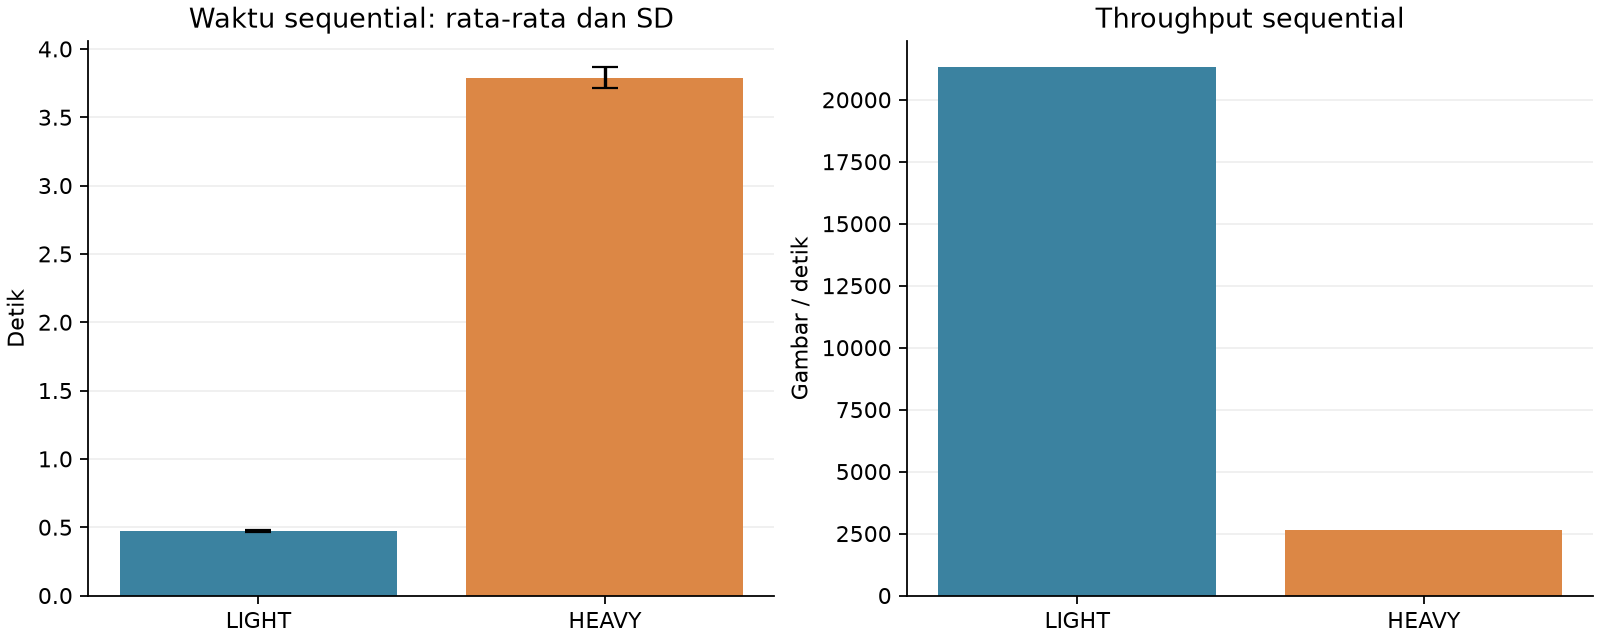

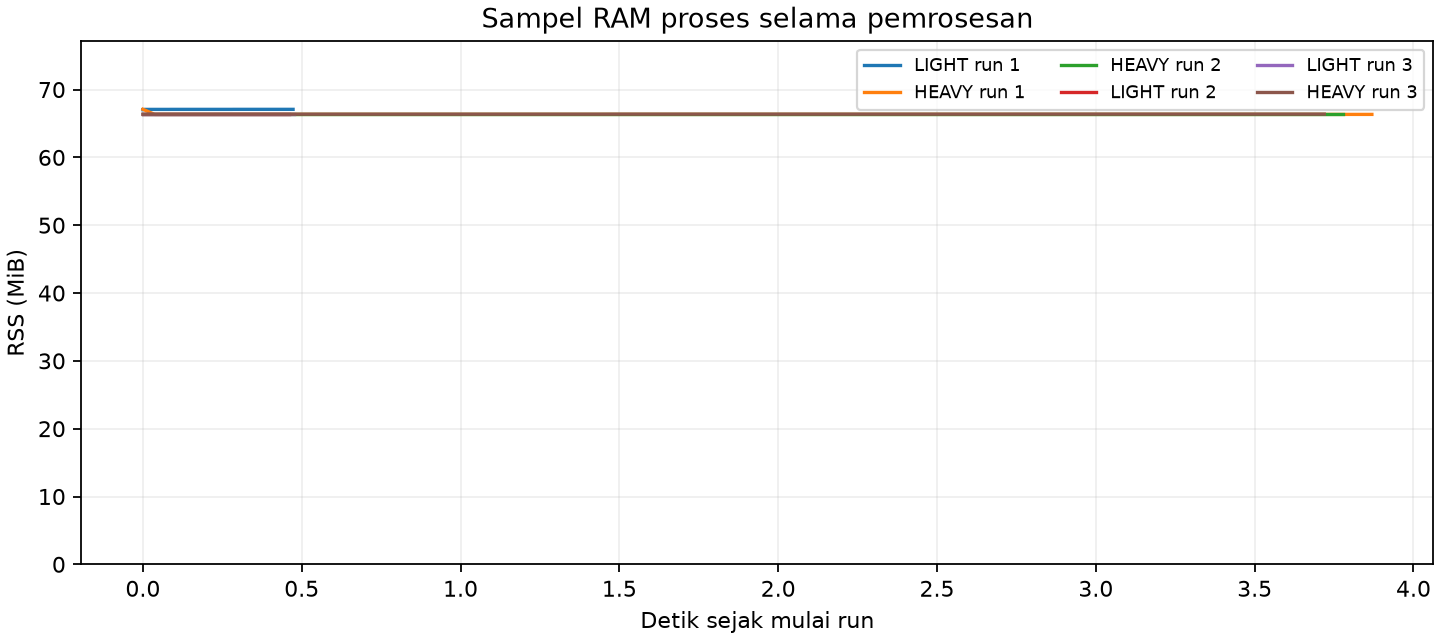

In [7]:
summary = pd.read_csv(RESULT_DIR / "summary.csv")
display(summary.round(3))
display(NotebookImage(filename=str(RESULT_DIR / "figures" / "time_throughput.png")))
display(NotebookImage(filename=str(RESULT_DIR / "figures" / "memory_samples.png")))

## 8. Analisis hasil

Analisis berikut dihitung dari CSV hasil eksekusi cell 5. Kalau notebook dijalankan ulang, angka pada analisis mengikuti run baru, sehingga saya tidak perlu mengganti angka secara manual. Saya membedakan hasil yang terukur dari dugaan penyebabnya.

In [8]:
analysis = (RESULT_DIR / "analysis.md").read_text(encoding="utf-8")
display(Markdown(analysis))

# Analisis Sequential Baseline

Pada tahap ini saya menguji pemrosesan gambar satu per satu sebagai baseline. Saya menggunakan batch pertama CIFAR-10 yang sama untuk LIGHT dan HEAVY, dengan parameter transformasi tetap. Hasil di bawah berasal dari run lokal yang tersimpan di folder ini.

## Hasil pengukuran

| Workload | Gambar/run | Run | Waktu rata-rata (s) | SD (s) | Throughput rata-rata (gambar/s) | CPU proses (%) | RSS maksimum tersampel (MiB) |
|---|---:|---:|---:|---:|---:|---:|---:|
| LIGHT | 10000 | 3 | 0.469 | 0.008 | 21305.8 | 95.4 | 67.09 |
| HEAVY | 10000 | 3 | 3.789 | 0.075 | 2639.8 | 96.9 | 67.10 |

## Pembacaan hasil

Rata-rata waktu HEAVY adalah 8.07 kali waktu LIGHT. Rasio ini membandingkan dua workload, bukan speedup metode paralel. HEAVY melakukan lebih banyak tahap transformasi, sehingga hasil tersebut saya baca dalam konteks jumlah operasi yang berbeda. Saya tidak menganggap HEAVY menghasilkan gambar yang lebih baik; pipeline ini sengaja dipakai sebagai pekerjaan eksperimen.

Variasi waktu LIGHT (SD/rata-rata) adalah 1.60%, sedangkan HEAVY 1.99%. Tiga pengulangan memberi gambaran variasi awal, tetapi belum cukup untuk memastikan penyebab perbedaan antar-run. Aktivitas aplikasi lain, scheduling, dan kondisi CPU merupakan kemungkinan, bukan penyebab yang sudah dibuktikan oleh pengukuran ini.

LIGHT selesai dalam waktu kurang dari satu detik pada eksperimen ini. Pada interval singkat, resolusi pencatatan CPU time dan gangguan kecil lebih terlihat dalam persentase CPU; angka sedikit di atas 100% tidak cukup untuk membuktikan adanya paralelisme pengolahan. Sebelum mengambil kesimpulan kuat tentang perbandingan metode, saya perlu menguji batch lebih besar atau menambah pengulangan secara konsisten pada semua metode.

CPU proses rata-rata tercatat 95.4% untuk LIGHT dan 96.9% untuk HEAVY. Skala yang saya gunakan menganggap 100% setara dengan satu logical CPU selama interval pengukuran. Komputer ini memiliki 22 logical CPU. Kolom kapasitas mesin pada CSV membagi CPU proses dengan jumlah logical CPU; nilai itu bukan pengukuran pemakaian CPU seluruh sistem. Saya juga tidak menyimpulkan proses selalu berjalan pada core fisik yang sama.

RSS maksimum tersampel adalah 67.09 MiB untuk LIGHT dan 67.10 MiB untuk HEAVY. RSS mencakup interpreter, library, dataset yang sudah dimuat, dan memori kerja. Nilai tersebut bukan hanya ukuran output gambar. Saya tidak menumpuk semua gambar hasil di RAM; setiap gambar hasil digunakan untuk hash kemudian diganti oleh hasil gambar berikutnya. Alokasi yang dipertahankan oleh library dan urutan run dapat memengaruhi RSS. Pengambilan sampel setiap 100 gambar juga dapat melewatkan puncak singkat, jadi angka ini bukan peak RAM mutlak.

Selisih maksimum RSS tersampel HEAVY dan LIGHT adalah 0.012 MiB. Saya tidak memakai selisih ini saja untuk menyimpulkan kebutuhan RAM kedua workload berbeda secara signifikan. Eksperimen ini memakai proses yang sama antar-run dan tidak mengukur alokasi setiap operasi secara terpisah. Grafik RAM memakai sumbu mulai dari nol agar perubahan kecil tidak terlihat berlebihan.

## Validasi dan batas pengukuran

Hash SHA-256 output konsisten antar-pengulangan untuk workload yang sama. Ini memeriksa reproduksibilitas byte output, bukan penilaian kualitas visual. Waktu mencakup konversi array ke gambar, transformasi, perhitungan hash output, loop, dan pemeriksaan RSS. Download, pemuatan dataset, warm-up, penulisan CSV, dan pembuatan grafik berada di luar timer. Overhead monitoring tetap ada; belum diukur terpisah.

LIGHT dan HEAVY dijalankan bergantian antar-pengulangan untuk mengurangi ketergantungan pada urutan, tetapi ini tidak menghilangkan pengaruh background task atau temperatur. Resize mengubah ukuran kerja menjadi 64 x 64; gambar input tetap berasal dari CIFAR-10 32 x 32. Efek memperbesar gambar ini harus dijaga sama ketika metode lain dibandingkan.

## Kesimpulan sementara

Saya sudah memperoleh baseline untuk dua tingkat pekerjaan. Speedup sequential ditetapkan 1,00 sebagai acuan. Saya belum bisa menyimpulkan threading atau multiprocessing lebih cepat karena keduanya belum diuji. Langkah berikutnya adalah menjalankan transformasi, jumlah gambar, dan kebijakan output yang sama dengan 2 dan 4 worker, lalu membandingkan waktu serta resource-nya.

## Sumber

- CIFAR-10: https://www.cs.toronto.edu/~kriz/cifar.html
- Pillow ImageFilter: https://pillow.readthedocs.io/en/stable/reference/ImageFilter.html
- psutil: https://psutil.readthedocs.io/
- Python perf_counter: https://docs.python.org/3/library/time.html#time.perf_counter


## 9. Hal yang perlu saya pahami sebelum melanjutkan

- Sequential menjadi baseline karena gambar diproses satu per satu dengan satu worker pengolah.
- LIGHT dan HEAVY berbeda dalam jumlah operasi. Rasio waktunya bukan speedup threading atau multiprocessing.
- CPU proses 100% tidak berarti seluruh CPU komputer terpakai 100%.
- RAM yang dicatat adalah RSS proses pada titik sampling, termasuk dataset dan library.
- Tiga pengulangan memberi hasil awal; kondisi komputer bisa memengaruhi variasi.
- Perbandingan metode berikutnya harus memakai dataset, transformasi, parameter, dan kebijakan output yang sama.

Kesimpulan tahap ini terbatas pada sequential. Saya belum menetapkan metode tercepat sebelum konfigurasi 2 dan 4 thread/process ikut diuji.

## Referensi

- [CIFAR-10 — Alex Krizhevsky, Vinod Nair, Geoffrey Hinton](https://www.cs.toronto.edu/~kriz/cifar.html), beserta laporan Alex Krizhevsky (2009), *Learning Multiple Layers of Features from Tiny Images*.
- [Pillow ImageFilter](https://pillow.readthedocs.io/en/stable/reference/ImageFilter.html).
- [psutil — informasi proses dan memori](https://psutil.readthedocs.io/).
- [Python time.perf_counter](https://docs.python.org/3/library/time.html#time.perf_counter).